# 04. Statistical Hypothesis Tests & Avoidable Escalation Gate Modeling
**Input:** `data/processed/tickets_clean.csv`  
**Outputs:** Test summary & model metrics in `reports/tables/`, diagnostic plots in `reports/figures/`, and serialized gate models in `models/`

**Scope:**
- **Section I:** Statistical hypothesis tests ($\alpha = 0.05$) validating operational claims with exact test statistics and $p$-values.
- **Section J:** Leakage-free predictive modeling at escalation intake (`Baseline`, `Logistic Regression`, `Random Forest`, `Gradient Boosting`, and `TF-IDF` on `description`), evaluated via 5-fold stratified CV and temporal holdout (Train: Jul–Aug, Test: Sep), plus calibration curves and feature importance diagnostics.

---
## I. Statistical Hypothesis Tests

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
TAB_DIR = PROJECT_ROOT / "reports" / "tables"
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(PROCESSED_DIR / "tickets_clean.csv")
for col in ["created_at", "first_response_at", "first_closed_at", "final_closed_at", "week_start"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")

esc_df = df[df["is_escalated"] == 1].copy()
test_results = []

# I1. Chi-Square: Avoidable escalation rate differs by category
ct_avoid_cat = pd.crosstab(esc_df["category"], esc_df["is_avoidable_esc"])
chi2_1, p_1, dof_1, _ = stats.chi2_contingency(ct_avoid_cat)
test_results.append({
    "hypothesis": "Avoidable escalation rate differs by category",
    "test": f"Chi-Square (dof={dof_1})",
    "statistic": f"chi2 = {chi2_1:.3f}",
    "p_value": p_1,
    "significant_0.05": p_1 < 0.05
})

# I2. Chi-Square: Reopen rate differs by agent
ct_reopen_ag = pd.crosstab(df["assigned_agent"], df["is_reopened"])
chi2_2, p_2, dof_2, _ = stats.chi2_contingency(ct_reopen_ag)
test_results.append({
    "hypothesis": "Reopen rate differs by assigned agent",
    "test": f"Chi-Square (dof={dof_2})",
    "statistic": f"chi2 = {chi2_2:.3f}",
    "p_value": p_2,
    "significant_0.05": p_2 < 0.05
})

# I3. Mann-Whitney U: Resolution time for escalated vs. non-escalated
res_esc = df.loc[df["is_escalated"] == 1, "resolution_hrs"].dropna()
res_non = df.loc[df["is_escalated"] == 0, "resolution_hrs"].dropna()
u_3, p_3 = stats.mannwhitneyu(res_esc, res_non, alternative="two-sided")
test_results.append({
    "hypothesis": f"Resolution time differs: Escalated ({res_esc.median():.1f}h) vs Non-Esc ({res_non.median():.1f}h)",
    "test": "Mann-Whitney U",
    "statistic": f"U = {u_3:,.1f}",
    "p_value": p_3,
    "significant_0.05": p_3 < 0.05
})

# I4. Mann-Whitney U: Resolution time for avoidable vs. real-fix escalations
res_avoid = esc_df.loc[esc_df["is_avoidable_esc"] == 1, "resolution_hrs"].dropna()
res_fixed = esc_df.loc[esc_df["is_avoidable_esc"] == 0, "resolution_hrs"].dropna()
u_4, p_4 = stats.mannwhitneyu(res_avoid, res_fixed, alternative="two-sided")
test_results.append({
    "hypothesis": f"Resolution time differs: Avoidable ({res_avoid.median():.1f}h) vs Fixed ({res_fixed.median():.1f}h)",
    "test": "Mann-Whitney U",
    "statistic": f"U = {u_4:,.1f}",
    "p_value": p_4,
    "significant_0.05": p_4 < 0.05
})

# I5. Kruskal-Wallis & Spearman Correlation: CSAT across engineering handoff counts
csat_valid = df.dropna(subset=["csat_score"]).copy()
groups_csat = [grp["csat_score"].values for _, grp in csat_valid.groupby("eng_handoffs")]
kw_stat, p_5_kw = stats.kruskal(*groups_csat)
rho_5, p_5_sp = stats.spearmanr(csat_valid["eng_handoffs"], csat_valid["csat_score"])
test_results.append({
    "hypothesis": "CSAT differs across engineering handoff counts (0, 1, 2, 3)",
    "test": "Kruskal-Wallis H",
    "statistic": f"H = {kw_stat:.3f}",
    "p_value": p_5_kw,
    "significant_0.05": p_5_kw < 0.05
})
test_results.append({
    "hypothesis": "CSAT correlates negatively with handoff count",
    "test": "Spearman Rank Corr",
    "statistic": f"rho = {rho_5:.3f}",
    "p_value": p_5_sp,
    "significant_0.05": p_5_sp < 0.05
})

# I6. Weekly Volume Trend vs Weekly Median Resolution Time (Full weeks only)
full_wks = df[df["is_partial_week"] == 0].copy()
wk_stats = full_wks.groupby("week_start").agg(
    weekly_volume=("ticket_id", "count"),
    median_res_hrs=("resolution_hrs", "median")
).reset_index()
wk_stats["week_num"] = np.arange(len(wk_stats))

sl_v, _, r_v, p_v, _ = stats.linregress(wk_stats["week_num"], wk_stats["weekly_volume"])
sl_r, _, r_r, p_r, _ = stats.linregress(wk_stats["week_num"], wk_stats["median_res_hrs"])

test_results.append({
    "hypothesis": f"Weekly ticket volume trends upward (+{sl_v:.2f} tkts/wk)",
    "test": "Linear Trend (OLS)",
    "statistic": f"r = {r_v:.3f}",
    "p_value": p_v,
    "significant_0.05": p_v < 0.05
})
test_results.append({
    "hypothesis": f"Weekly median resolution time stays flat ({sl_r:+.2f} hrs/wk)",
    "test": "Linear Trend (OLS)",
    "statistic": f"r = {r_r:.3f}",
    "p_value": p_r,
    "significant_0.05": p_r < 0.05
})

hyp_df = pd.DataFrame(test_results)
hyp_df["p_value_fmt"] = hyp_df["p_value"].apply(lambda p: f"{p:.4e}" if p < 0.001 else f"{p:.4f}")
hyp_df.to_csv(TAB_DIR / "i1_hypothesis_tests.csv", index=False)

print("=== SECTION I. STATISTICAL HYPOTHESIS TEST RESULTS ===")
display(hyp_df[["hypothesis", "test", "statistic", "p_value_fmt", "significant_0.05"]])

=== SECTION I. STATISTICAL HYPOTHESIS TEST RESULTS ===


,hypothesis,test,statistic,p_value_fmt,significant_0.05
0,Avoidable escalation rate differs by category,Chi-Square (dof=9),chi2 = 8.908,0.4458,False
1,Reopen rate differs by assigned agent,Chi-Square (dof=7),chi2 = 102.078,4.0132e-19,True
2,Resolution time differs: Escalated (86.8h) vs Non-Esc (12.6h),Mann-Whitney U,"U = 404,483.5",5.7506e-162,True
3,Resolution time differs: Avoidable (103.1h) vs Fixed (64.8h),Mann-Whitney U,"U = 35,114.5",5.5762e-13,True
4,"CSAT differs across engineering handoff counts (0, 1, 2, 3)",Kruskal-Wallis H,H = 165.587,1.1411e-35,True
5,CSAT correlates negatively with handoff count,Spearman Rank Corr,rho = -0.472,2.7589e-37,True
6,Weekly ticket volume trends upward (+5.42 tkts/wk),Linear Trend (OLS),r = 0.861,3.2696e-04,True
7,Weekly median resolution time stays flat (+0.34 hrs/wk),Linear Trend (OLS),r = 0.183,0.5702,False


---
## J. Predictive Modeling: Avoidable Escalation Gate
**Target:** `is_avoidable_esc` (1 = avoidable escalation, 0 = legitimate `Fixed` escalation) among escalated tickets (`n = 486`).  
**Leakage Guard:** Only features known *at or before the moment L1 escalates* are permitted (`category`, `priority`, `channel`, `client_tier`, `assigned_agent`, `description`, `hour_of_day`, `weekday`, `hrs_to_first_response`, `is_repeat_contact`, and prior client ticket count). Post-escalation columns (`eng_outcome`, `eng_handoffs`, `first_closed_at`, `final_closed_at`, `resolution_hrs`, `reopen_count`, `csat_score`) are strictly excluded.

In [2]:
import joblib
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_score,
    recall_score, f1_score
)

# 1. Compute leakage-free historical client ticket count prior to current ticket
df_chrono = df.sort_values(["created_at", "ticket_id"]).reset_index(drop=True).copy()
df_chrono["client_prior_tickets"] = df_chrono.groupby("client_id").cumcount()

# Filter to escalated tickets only (n = 486)
model_df = df_chrono[df_chrono["is_escalated"] == 1].reset_index(drop=True).copy()

# 2. Explicit Leakage Guard Check
FORBIDDEN_LEAKAGE_COLS = {
    "eng_outcome", "eng_handoffs", "eng_ticket_id", "first_closed_at",
    "final_closed_at", "hrs_to_first_close", "hrs_to_final_close",
    "resolution_hrs", "reopen_count", "is_reopened", "csat_score",
    "status", "is_open", "open_age_hrs", "is_avoidable_esc", "is_returned_to_l1"
}

cat_features = ["category", "priority", "channel", "client_tier", "assigned_agent", "weekday"]
num_features = ["hrs_to_first_response", "hour_of_day", "is_repeat_contact", "client_prior_tickets"]
text_feature = "description"

selected_features = cat_features + num_features + [text_feature]
assert len(set(selected_features).intersection(FORBIDDEN_LEAKAGE_COLS)) == 0, "LEAKAGE DETECTED!"
print("Leakage check passed: 0 post-escalation features in feature matrix.")

X = model_df[selected_features].copy()
y = model_df["is_avoidable_esc"].values

# 3. Temporal Split: Train = Jul–Aug, Test = Sep
is_sep = model_df["created_at"].dt.month == 9
X_train, y_train = X[~is_sep].reset_index(drop=True), y[~is_sep]
X_test, y_test = X[is_sep].reset_index(drop=True), y[is_sep]

print(f"Total Escalated Samples: {len(X)} | Avoidable Base Rate: {y.mean()*100:.2f}%")
print(f"Temporal Split -> Train (Jul-Aug): {len(X_train)} ({y_train.mean()*100:.1f}% pos) | Test (Sep): {len(X_test)} ({y_test.mean()*100:.1f}% pos)")

# 4. Preprocessing Pipelines
tabular_prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features)
])

tfidf_prep = ColumnTransformer([
    ("tfidf", TfidfVectorizer(max_features=300, ngram_range=(1, 2), stop_words="english"), text_feature)
])

hybrid_prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
    ("tfidf", TfidfVectorizer(max_features=300, ngram_range=(1, 2), stop_words="english"), text_feature)
])

models = {
    "Logistic Regression": Pipeline([
        ("prep", tabular_prep),
        ("clf", LogisticRegression(max_iter=1000, C=0.5, random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("prep", tabular_prep),
        ("clf", RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=5, random_state=42))
    ]),
    "Gradient Boosting": Pipeline([
        ("prep", tabular_prep),
        ("clf", GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=3, random_state=42))
    ]),
    "TF-IDF Text Model": Pipeline([
        ("prep", tfidf_prep),
        ("clf", LogisticRegression(max_iter=1000, C=1.0, random_state=42))
    ]),
    "Hybrid (Tabular + TF-IDF)": Pipeline([
        ("prep", hybrid_prep),
        ("clf", LogisticRegression(max_iter=1000, C=0.5, random_state=42))
    ])
}

THRESHOLD = 0.55  # Operating threshold aligned with ~57% avoidable base rate

def eval_probs(y_true, y_prob, thresh=THRESHOLD):
    y_pred = (y_prob >= thresh).astype(int)
    return {
        "ROC_AUC": roc_auc_score(y_true, y_prob),
        "PR_AUC": average_precision_score(y_true, y_prob),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0)
    }

# 5. 5-Fold Stratified Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []

# Baseline OOF predictions (historical category avoidable rate)
oof_base = np.zeros(len(X))
for tr_idx, va_idx in cv.split(X, y):
    cat_rates = pd.Series(y[tr_idx], index=X.iloc[tr_idx]["category"]).groupby(level=0).mean()
    oof_base[va_idx] = X.iloc[va_idx]["category"].map(cat_rates).fillna(y[tr_idx].mean())
cv_rows.append({"Model": "Baseline (Category Rate)", **eval_probs(y, oof_base)})

for name, pipe in models.items():
    oof_probs = cross_val_predict(pipe, X, y, cv=cv, method="predict_proba")[:, 1]
    cv_rows.append({"Model": name, **eval_probs(y, oof_probs)})

cv_results_df = pd.DataFrame(cv_rows).set_index("Model")
cv_results_df.to_csv(TAB_DIR / "j1_cv_model_comparison.csv")
print(f"\n=== J1. 5-FOLD STRATIFIED CV RESULTS (Threshold = {THRESHOLD}) ===")
display(cv_results_df)

# 6. Temporal Holdout Evaluation (Train: Jul-Aug | Test: Sep)
cat_train_rates = pd.Series(y_train, index=X_train["category"]).groupby(level=0).mean()
base_test_probs = X_test["category"].map(cat_train_rates).fillna(y_train.mean()).values

time_rows = [{"Model": "Baseline (Category Rate)", **eval_probs(y_test, base_test_probs)}]
fitted_models = {}

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe
    test_probs = pipe.predict_proba(X_test)[:, 1]
    time_rows.append({"Model": name, **eval_probs(y_test, test_probs)})

time_results_df = pd.DataFrame(time_rows).set_index("Model")
time_results_df.to_csv(TAB_DIR / "j2_temporal_split_comparison.csv")
print(f"\n=== J2. TEMPORAL VALIDATION RESULTS (TRAIN: JUL-AUG | TEST: SEP | Threshold = {THRESHOLD}) ===")
display(time_results_df)

# Save best model artifact to models/
best_model_name = time_results_df["ROC_AUC"].idxmax()
joblib.dump(fitted_models[best_model_name], MODEL_DIR / "avoidable_escalation_gate.joblib")
print(f"\nSaved top temporal model ('{best_model_name}') to models/avoidable_escalation_gate.joblib")

Leakage check passed: 0 post-escalation features in feature matrix.
Total Escalated Samples: 486 | Avoidable Base Rate: 56.58%
Temporal Split -> Train (Jul-Aug): 297 (55.2% pos) | Test (Sep): 189 (58.7% pos)

=== J1. 5-FOLD STRATIFIED CV RESULTS (Threshold = 0.55) ===


,ROC_AUC,PR_AUC,Precision,Recall,F1
Model,,,,,
Baseline (Category Rate),0.495399,0.561977,0.561702,0.480000,0.517647
Logistic Regression,0.566118,0.617896,0.614504,0.585455,0.599628
Random Forest,0.559673,0.613485,0.589404,0.647273,0.616984
Gradient Boosting,0.550487,0.600407,0.605166,0.596364,0.600733
TF-IDF Text Model,0.466928,0.542453,0.552347,0.556364,0.554348
Hybrid (Tabular + TF-IDF),0.546247,0.593802,0.590734,0.556364,0.573034



=== J2. TEMPORAL VALIDATION RESULTS (TRAIN: JUL-AUG | TEST: SEP | Threshold = 0.55) ===


,ROC_AUC,PR_AUC,Precision,Recall,F1
Model,,,,,
Baseline (Category Rate),0.428505,0.566524,0.508621,0.531532,0.519824
Logistic Regression,0.544121,0.636577,0.651685,0.522523,0.580000
Random Forest,0.515939,0.610029,0.616438,0.405405,0.489130
Gradient Boosting,0.527836,0.610398,0.590909,0.468468,0.522613
TF-IDF Text Model,0.443405,0.550126,0.574074,0.558559,0.566210
Hybrid (Tabular + TF-IDF),0.529684,0.616803,0.589474,0.504505,0.543689



Saved top temporal model ('Logistic Regression') to models/avoidable_escalation_gate.joblib


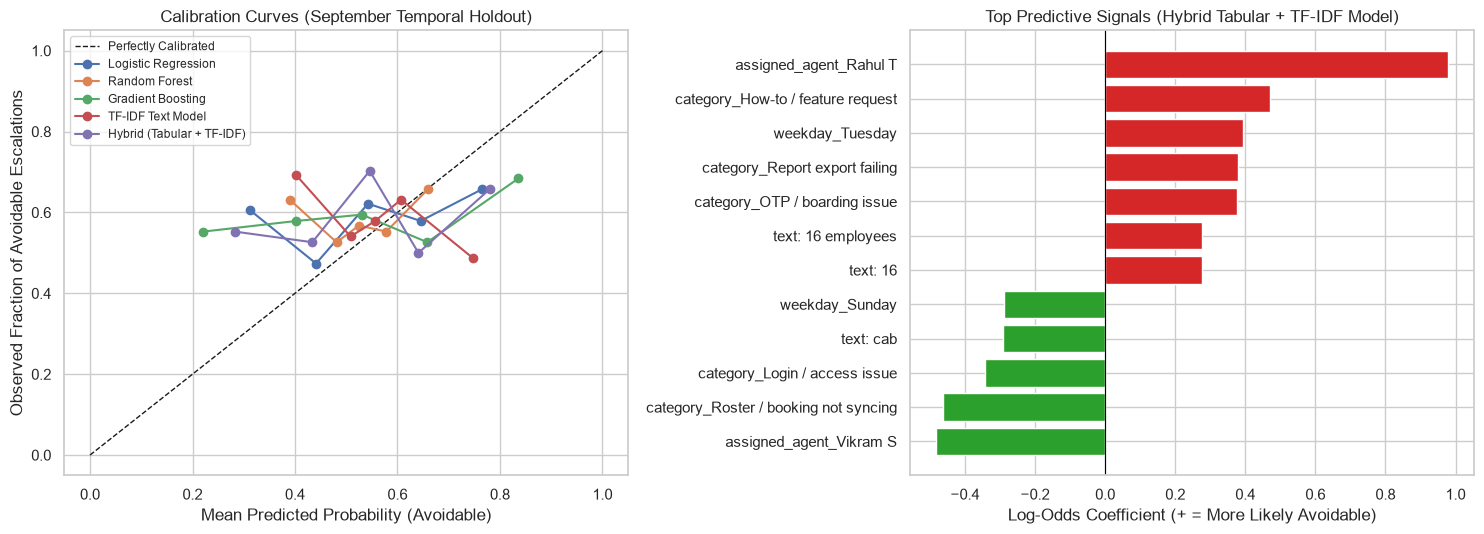

=== TOP 12 GRADIENT BOOSTING TABULAR FEATURE IMPORTANCES ===


,feature,importance
0,hrs_to_first_response,0.215370
30,assigned_agent_Rahul T,0.116068
3,client_prior_tickets,0.108455
1,hour_of_day,0.107687
28,assigned_agent_Neha P,0.055568
11,category_OTP / boarding issue,0.045645
13,category_Roster / booking not syncing,0.039657
34,weekday_Monday,0.029301
15,priority_P2,0.027518
24,client_tier_SMB,0.026348


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Plot 1: Calibration Curves on September Holdout
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1, label="Perfectly Calibrated")
for name in ["Logistic Regression", "Random Forest", "Gradient Boosting", "TF-IDF Text Model", "Hybrid (Tabular + TF-IDF)"]:
    probs = fitted_models[name].predict_proba(X_test)[:, 1]
    frac_pos, mean_pred = calibration_curve(y_test, probs, n_bins=5, strategy="quantile")
    axes[0].plot(mean_pred, frac_pos, marker="o", label=name)

axes[0].set_xlabel("Mean Predicted Probability (Avoidable)")
axes[0].set_ylabel("Observed Fraction of Avoidable Escalations")
axes[0].set_title("Calibration Curves (September Temporal Holdout)")
axes[0].legend(loc="upper left", fontsize=8.5)

# Plot 2: Top 12 Drivers from Hybrid Model (Logistic Regression Coefficients)
hyb_pipe = fitted_models["Hybrid (Tabular + TF-IDF)"]
prep = hyb_pipe.named_steps["prep"]
cat_names = prep.named_transformers_["cat"].get_feature_names_out(cat_features)
tfidf_names = [f"text: {w}" for w in prep.named_transformers_["tfidf"].get_feature_names_out()]
all_features = np.concatenate([num_features, cat_names, tfidf_names])

coefs = hyb_pipe.named_steps["clf"].coef_[0]
coef_df = pd.DataFrame({"feature": all_features, "coef": coefs})
top_drivers = pd.concat([
    coef_df.sort_values("coef", ascending=False).head(7),
    coef_df.sort_values("coef", ascending=True).head(5)
]).sort_values("coef", ascending=True)

colors = ["#2ca02c" if c < 0 else "#d62728" for c in top_drivers["coef"]]
axes[1].barh(top_drivers["feature"], top_drivers["coef"], color=colors)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Log-Odds Coefficient (+ = More Likely Avoidable)")
axes[1].set_title("Top Predictive Signals (Hybrid Tabular + TF-IDF Model)")

plt.tight_layout()
plt.savefig(FIG_DIR / "j_model_calibration_and_features.png", dpi=150)
plt.show()

# Also display Gradient Boosting Tabular Feature Importances
gb_pipe = fitted_models["Gradient Boosting"]
gb_cat_names = gb_pipe.named_steps["prep"].named_transformers_["cat"].get_feature_names_out(cat_features)
gb_feat_names = np.concatenate([num_features, gb_cat_names])
gb_imp = pd.DataFrame({
    "feature": gb_feat_names,
    "importance": gb_pipe.named_steps["clf"].feature_importances_
}).sort_values("importance", ascending=False).head(12)

print("=== TOP 12 GRADIENT BOOSTING TABULAR FEATURE IMPORTANCES ===")
display(gb_imp)